In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

print("=" * 60)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 32 - FEATURE OUTLIER ANALYSIS")
print("=" * 60)

print("\nLibraries imported successfully!")
print("Today's Goal: Explore feature distributions and identify potential outliers.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 32 - FEATURE OUTLIER ANALYSIS

Libraries imported successfully!
Today's Goal: Explore feature distributions and identify potential outliers.


In [4]:
# DAY 32 - LOAD VALIDATED STUDENT DATASET

current_dir = Path.cwd()

possible_paths = [
    current_dir / "day29_validated_student_features.csv",
    current_dir.parent / "day29_validated_student_features.csv",
    current_dir.parent.parent / "day29_validated_student_features.csv",
    current_dir / "Data" / "day29_validated_student_features.csv",
    current_dir.parent / "Data" / "day29_validated_student_features.csv",
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is not None:
    df = pd.read_csv(dataset_path)

    print("Validated dataset loaded successfully!")
    print("File location:", dataset_path.resolve())
    print("Dataset shape:", df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nFirst 5 Records:")
    display(df.head())

else:
    print("Validated dataset file not found.")
    print("Current directory:", current_dir)
    print("Please check whether Day 29's dataset was saved successfully.")

Validated dataset loaded successfully!
File location: C:\Internship_project\Data\day29_validated_student_features.csv
Dataset shape: (1, 4)

Column Names:
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

First 5 Records:


,study_hours,attendance,previous_score,assignments_completed
0,6,90,78,9


In [6]:
# DAY 32 - PREPARE NUMERIC FEATURES

if "df" in globals() and not df.empty:

    expected_features = [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]

    available_features = [
        col for col in expected_features
        if col in df.columns
    ]

    missing_features = [
        col for col in expected_features
        if col not in df.columns
    ]

    print("Available Features:", available_features)
    print("Missing Expected Features:", missing_features)

    if available_features:
        X_outlier = df[available_features].copy()

        # Convert feature columns to numeric values
        for col in X_outlier.columns:
            X_outlier[col] = pd.to_numeric(
                X_outlier[col],
                errors="coerce"
            )

        # Replace infinite values with missing values
        X_outlier = X_outlier.replace(
            [np.inf, -np.inf],
            np.nan
        )

        print("\nFeature Dataset Shape:", X_outlier.shape)

        print("\nFirst 5 Feature Records:")
        display(X_outlier.head())

        print("\nMissing Values in Each Feature:")
        display(X_outlier.isnull().sum().to_frame("Missing Count"))

    else:
        print("No expected input features were found.")

else:
    print("Please run Cell 2 first and load the validated dataset.")

Available Features: ['study_hours', 'attendance', 'previous_score', 'assignments_completed']
Missing Expected Features: []

Feature Dataset Shape: (1, 4)

First 5 Feature Records:


,study_hours,attendance,previous_score,assignments_completed
0,6,90,78,9



Missing Values in Each Feature:


,Missing Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0


In [8]:
# DAY 32 - FEATURE DESCRIPTIVE STATISTICS

if "X_outlier" in globals() and not X_outlier.empty:

    print("=" * 60)
    print("FEATURE DESCRIPTIVE STATISTICS")
    print("=" * 60)

    feature_stats = X_outlier.describe().T

    # Add median and missing-value counts
    feature_stats["median"] = X_outlier.median()
    feature_stats["missing_values"] = X_outlier.isnull().sum()

    display(feature_stats.round(3))

    print("\nInterpretation Guide:")
    print("- Mean: Average value of a feature.")
    print("- Std: How widely values vary around the mean.")
    print("- 25% and 75%: First and third quartiles.")
    print("- Min and Max: Smallest and largest observed values.")
    print("- Large differences between quartiles and extremes may")
    print("  indicate values that need further investigation.")

else:
    print("Please run Cell 3 first to prepare the feature dataset.")

FEATURE DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,median,missing_values
study_hours,1.0,6.0,NaN,6.0,6.0,6.0,6.0,6.0,6.0,0
attendance,1.0,90.0,NaN,90.0,90.0,90.0,90.0,90.0,90.0,0
previous_score,1.0,78.0,NaN,78.0,78.0,78.0,78.0,78.0,78.0,0
assignments_completed,1.0,9.0,NaN,9.0,9.0,9.0,9.0,9.0,9.0,0



Interpretation Guide:
- Mean: Average value of a feature.
- Std: How widely values vary around the mean.
- 25% and 75%: First and third quartiles.
- Min and Max: Smallest and largest observed values.
- Large differences between quartiles and extremes may
  indicate values that need further investigation.


C:\Users\Himansi\AppData\Local\Temp\ipykernel_28668\603434814.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 1].boxplot(
C:\Users\Himansi\AppData\Local\Temp\ipykernel_28668\603434814.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 1].boxplot(
C:\Users\Himansi\AppData\Local\Temp\ipykernel_28668\603434814.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 1].boxplot(
C:\Users\Himansi\AppData\Local\Temp\ipykernel_28668\603434814.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 1].boxplot(


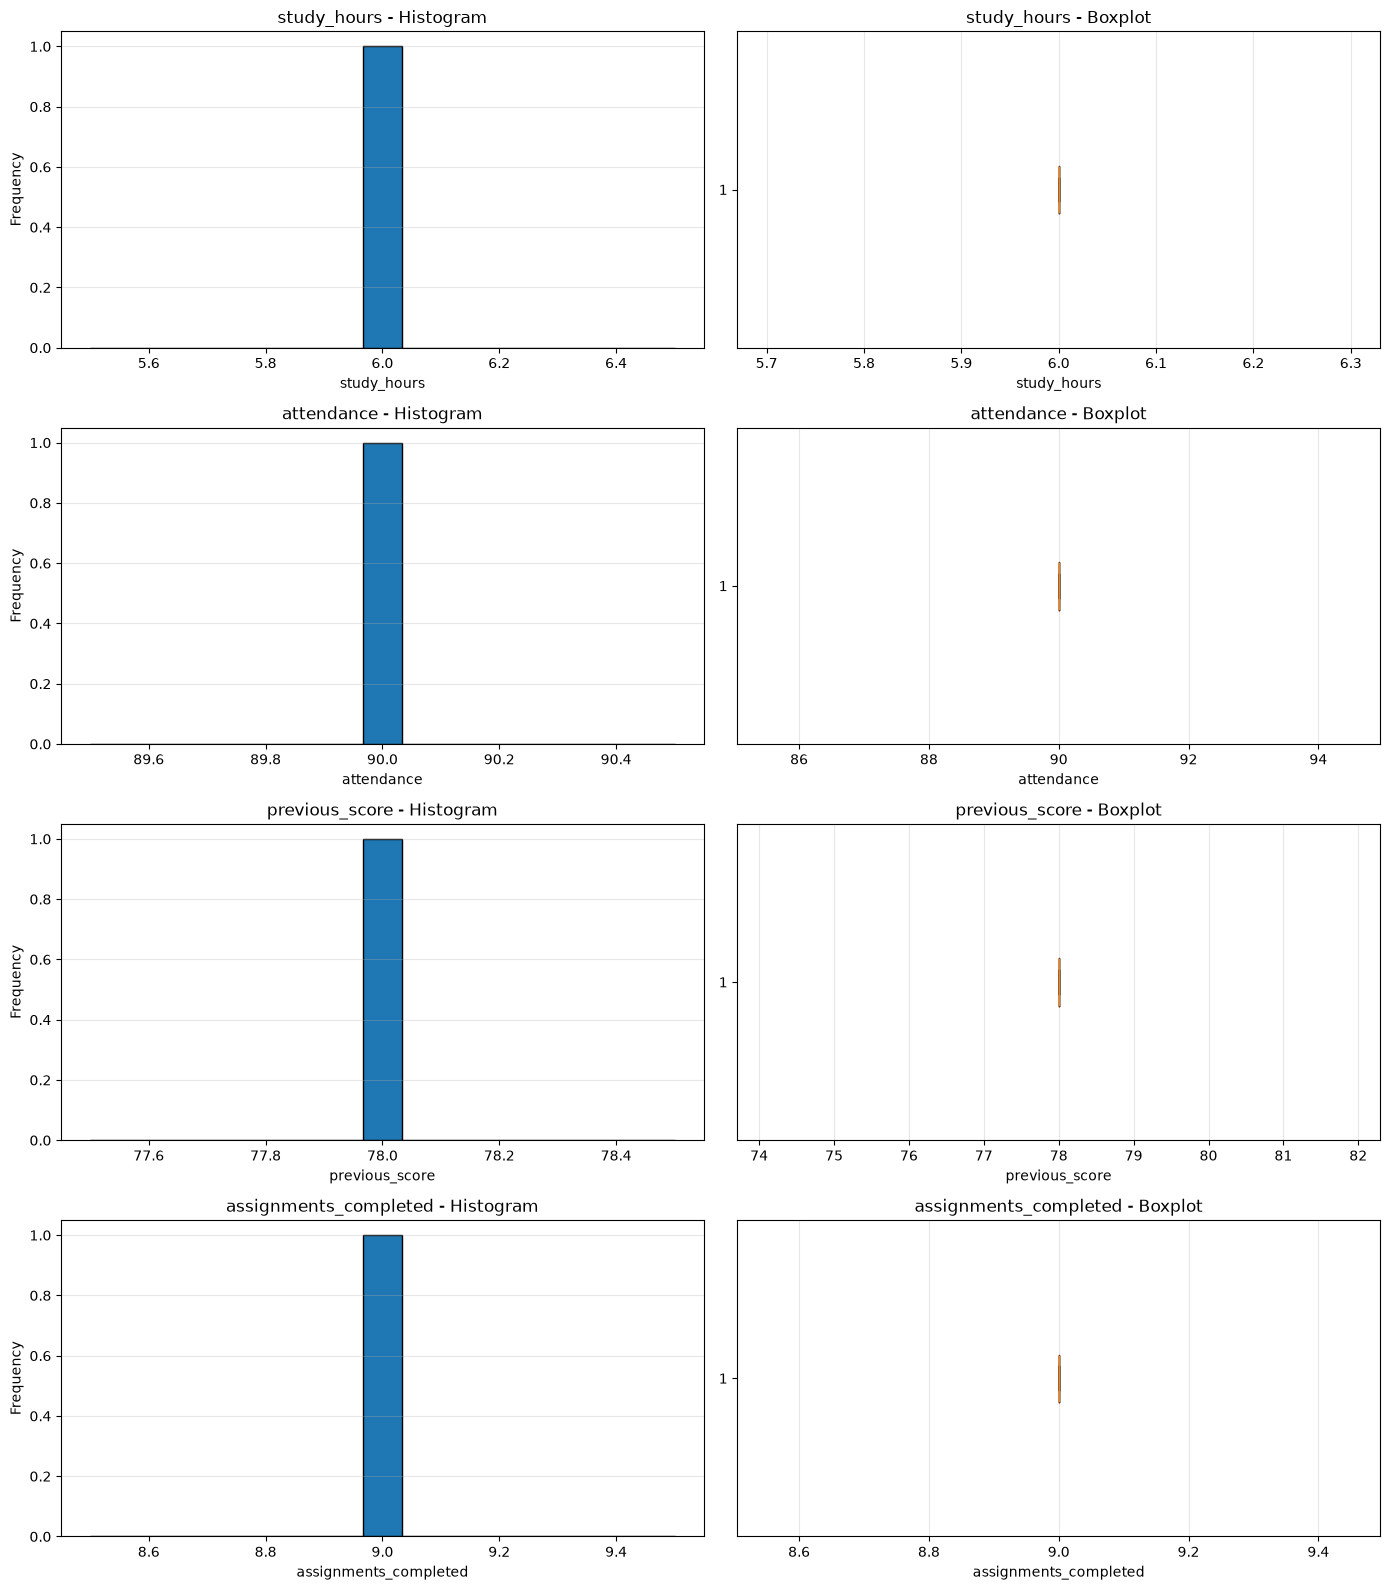

In [10]:
# DAY 32 - FEATURE DISTRIBUTION VISUALIZATION

if "X_outlier" in globals() and not X_outlier.empty:

    features = X_outlier.columns.tolist()

    fig, axes = plt.subplots(
        nrows=len(features),
        ncols=2,
        figsize=(14, 4 * len(features))
    )

    axes = np.atleast_2d(axes)

    for i, col in enumerate(features):

        values = X_outlier[col].dropna()

        # Histogram
        axes[i, 0].hist(
            values,
            bins=15,
            edgecolor="black"
        )
        axes[i, 0].set_title(f"{col} - Histogram")
        axes[i, 0].set_xlabel(col)
        axes[i, 0].set_ylabel("Frequency")
        axes[i, 0].grid(axis="y", alpha=0.3)

        # Boxplot
        axes[i, 1].boxplot(
            values,
            vert=False
        )
        axes[i, 1].set_title(f"{col} - Boxplot")
        axes[i, 1].set_xlabel(col)
        axes[i, 1].grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

else:
    print("Please run Cell 3 first to prepare the features.")

In [12]:
# DAY 32 - IQR-BASED OUTLIER DETECTION

if "X_outlier" in globals() and not X_outlier.empty:

    outlier_summary = []
    outlier_flags = pd.DataFrame(
        False,
        index=X_outlier.index,
        columns=X_outlier.columns
    )

    for col in X_outlier.columns:

        values = X_outlier[col].dropna()

        if values.empty:
            print(f"Skipping {col}: no valid numeric values.")
            continue

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        flags = (
            (X_outlier[col] < lower_bound) |
            (X_outlier[col] > upper_bound)
        ).fillna(False)

        outlier_flags[col] = flags

        outlier_count = int(flags.sum())
        valid_count = int(values.count())

        outlier_summary.append({
            "feature": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": outlier_count,
            "valid_count": valid_count,
            "outlier_percentage": (
                outlier_count / valid_count * 100
                if valid_count > 0 else 0
            )
        })

    outlier_summary_df = pd.DataFrame(outlier_summary)

    print("IQR Outlier Detection Summary:")
    display(outlier_summary_df.round(3))

    print("\nTotal rows flagged in at least one feature:",
          int(outlier_flags.any(axis=1).sum()))

    print("Total rows with no flagged feature:",
          int((~outlier_flags.any(axis=1)).sum()))

else:
    print("Please run Cell 3 first to prepare the features.")

IQR Outlier Detection Summary:


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,valid_count,outlier_percentage
0,study_hours,6.0,6.0,0.0,6.0,6.0,0,1,0.0
1,attendance,90.0,90.0,0.0,90.0,90.0,0,1,0.0
2,previous_score,78.0,78.0,0.0,78.0,78.0,0,1,0.0
3,assignments_completed,9.0,9.0,0.0,9.0,9.0,0,1,0.0



Total rows flagged in at least one feature: 0
Total rows with no flagged feature: 1


In [14]:
# DAY 32 - DISPLAY POTENTIAL OUTLIER RECORDS

if "outlier_flags" in globals() and "outlier_summary_df" in globals():

    outlier_records = []

    for col in X_outlier.columns:

        if col not in outlier_summary_df["feature"].values:
            continue

        limits = outlier_summary_df.loc[
            outlier_summary_df["feature"] == col
        ].iloc[0]

        flagged_indices = outlier_flags.index[
            outlier_flags[col]
        ]

        for idx in flagged_indices:
            outlier_records.append({
                "row_index": idx,
                "feature": col,
                "observed_value": X_outlier.loc[idx, col],
                "lower_bound": limits["lower_bound"],
                "upper_bound": limits["upper_bound"],
                "outlier_type": (
                    "Below lower bound"
                    if X_outlier.loc[idx, col] < limits["lower_bound"]
                    else "Above upper bound"
                )
            })

    outlier_records_df = pd.DataFrame(outlier_records)

    if not outlier_records_df.empty:
        print("Potential Outlier Records:")
        display(outlier_records_df.round(3))

        print("\nTotal flagged feature values:",
              len(outlier_records_df))
    else:
        print("No potential outliers detected using the IQR method.")

else:
    print("Please run Cell 6 first.")

No potential outliers detected using the IQR method.


In [16]:
# DAY 32 - OUTLIER SUMMARY

if "outlier_summary_df" in globals() and not outlier_summary_df.empty:

    summary_columns = [
        "feature",
        "valid_count",
        "outlier_count",
        "outlier_percentage",
        "lower_bound",
        "upper_bound"
    ]

    outlier_final_summary = outlier_summary_df[
        summary_columns
    ].copy()

    outlier_final_summary["outlier_percentage"] = (
        outlier_final_summary["outlier_percentage"].round(2)
    )

    print("=" * 60)
    print("FINAL OUTLIER SUMMARY")
    print("=" * 60)

    display(outlier_final_summary)

    total_flagged_rows = int(
        outlier_flags.any(axis=1).sum()
    )

    total_rows = len(X_outlier)

    print("\nTotal dataset rows:", total_rows)
    print("Rows with at least one potential outlier:", total_flagged_rows)

    if total_rows > 0:
        print(
            "Percentage of rows flagged:",
            round(total_flagged_rows / total_rows * 100, 2),
            "%"
        )

    print("\nReminder: IQR flags are investigation signals,")
    print("not proof that a value is incorrect.")

else:
    print("Please run Cell 6 first to generate the outlier summary.")

FINAL OUTLIER SUMMARY


,feature,valid_count,outlier_count,outlier_percentage,lower_bound,upper_bound
0,study_hours,1,0,0.0,6.0,6.0
1,attendance,1,0,0.0,90.0,90.0
2,previous_score,1,0,0.0,78.0,78.0
3,assignments_completed,1,0,0.0,9.0,9.0



Total dataset rows: 1
Rows with at least one potential outlier: 0
Percentage of rows flagged: 0.0 %

Reminder: IQR flags are investigation signals,
not proof that a value is incorrect.


In [18]:
# DAY 32 - SAVE OUTLIER ANALYSIS REPORTS

from pathlib import Path

if (
    "outlier_final_summary" in globals()
    and "outlier_records_df" in globals()
):

    # Save reports in the current notebook directory
    output_dir = Path.cwd()
    output_dir.mkdir(parents=True, exist_ok=True)

    summary_path = output_dir / "day32_outlier_summary.csv"
    records_path = output_dir / "day32_potential_outlier_records.csv"

    outlier_final_summary.to_csv(
        summary_path,
        index=False
    )

    outlier_records_df.to_csv(
        records_path,
        index=False
    )

    print("Outlier analysis reports saved successfully!")
    print("\nSummary report:")
    print(summary_path.resolve())

    print("\nPotential outlier records:")
    print(records_path.resolve())

    print("\nSummary report shape:", outlier_final_summary.shape)
    print("Flagged-record report shape:", outlier_records_df.shape)

else:
    print("Please run Cells 6, 7, and 8 before saving the reports.")

Outlier analysis reports saved successfully!

Summary report:
C:\Internship_project\Data\Data\day32_outlier_summary.csv

Potential outlier records:
C:\Internship_project\Data\Data\day32_potential_outlier_records.csv

Summary report shape: (4, 6)
Flagged-record report shape: (0, 0)


In [19]:
# DAY 32 - FINAL SUMMARY

print("=" * 60)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 32 - FEATURE OUTLIER ANALYSIS")
print("=" * 60)

if "X_outlier" in globals() and "outlier_summary_df" in globals():

    print("\n1. Dataset Overview")
    print("Total rows:", len(X_outlier))
    print("Features analyzed:", len(X_outlier.columns))
    print("Feature names:", X_outlier.columns.tolist())

    print("\n2. Outlier Detection")
    print("Method: Interquartile Range (IQR)")

    print("\nFeature-wise Outlier Counts:")
    display(
        outlier_summary_df[
            ["feature", "outlier_count", "outlier_percentage"]
        ].round(2)
    )

    print("\n3. Output Files")
    for filename in [
        "day32_outlier_summary.csv",
        "day32_potential_outlier_records.csv"
    ]:
        file_path = Path.cwd() / filename
        print(f"{filename}: {'Saved' if file_path.exists() else 'Not found'}")

    print("\n4. Important Notes")
    print("- Potential outliers were identified using IQR limits.")
    print("- Flagged values were not automatically removed.")
    print("- Domain knowledge is required before changing any value.")
    print("- Actual student outcomes are needed to validate prediction quality.")

    print("\nDay 32 analysis completed!")

else:
    print("Please run the previous cells successfully before this summary.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 32 - FEATURE OUTLIER ANALYSIS

1. Dataset Overview
Total rows: 1
Features analyzed: 4
Feature names: ['study_hours', 'attendance', 'previous_score', 'assignments_completed']

2. Outlier Detection
Method: Interquartile Range (IQR)

Feature-wise Outlier Counts:


,feature,outlier_count,outlier_percentage
0,study_hours,0,0.0
1,attendance,0,0.0
2,previous_score,0,0.0
3,assignments_completed,0,0.0



3. Output Files
day32_outlier_summary.csv: Saved
day32_potential_outlier_records.csv: Saved

4. Important Notes
- Potential outliers were identified using IQR limits.
- Flagged values were not automatically removed.
- Domain knowledge is required before changing any value.
- Actual student outcomes are needed to validate prediction quality.

Day 32 analysis completed!
